## Keyword baseline sentiment

Baseline text signals for GME / AMC / BB using the **Loughran-McDonald (LM) financial dictionary**.

The fields in the `comments*.csv` are:

| Field | Description |
|---|---|
| `author` | Reddit username of the commenter. |
| `body` | The actual text content of the comment. |
| `controversiality` | Reddit indicator showing whether the comment received controversial votes. |
| `created_utc` | Unix timestamp indicating when the comment was created. |
| `distinguished` | Indicates whether the comment was given a special moderator/admin designation. |
| `id` | Unique identifier for the comment. |
| `is_submitter` | Indicates whether the commenter is the author of the submission. |
| `link_id` | Unique identifier of the submission containing the comment. |
| `parent_id` | Identifier of the comment or submission that this comment directly replies to. |
| `score` | Net Reddit vote score representing the comment's engagement. |
| `stickied` | Indicates whether the comment was pinned by a moderator. |
| `subreddit` | Name of the subreddit where the comment was posted. |
| `ups` | Number of upvotes received by the comment; largely redundant with `score` for this analysis. |



We calculate the sentiment score

$$S_d = \frac{N_{\text{bullish},d}-N_{\text{bearish},d}}
{N_{\text{bullish},d}+N_{\text{bearish},d}+N_{\text{neutral},d}}$$

and assess the stability of the performance for subgroup of posts, via the following metrics:

- $\text{Coverage Rate}=\frac{N_\text{Informative posts}}{N_\text{Total posts}}$
- Mean daily between-subgroup standard deviation of sentiment scores.



Result:
`wallstreetbets_BB_Nov30` sample gives
- coverage rate=45\%
- mean daily between-subgroup standard deviation of sentiment scores=0.192

## 0. Set up the environment

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


import os
from google.colab import drive

# pysentiment2 ships the full LM master dictionary (Positive / Negative / Uncertainty / ...)
!pip -q install pysentiment2
import pysentiment2, os

# for keyword counting
import re
from collections import Counter

In [2]:
# Locate google-drive folder
drive.mount(f"/content/drive/")
print(os.getcwd())

project_path = "/content/drive/MyDrive/Colab Notebooks/dl-quant_project/DataSource"

Mounted at /content/drive/
/content


In [3]:
pd.set_option("display.max_colwidth", None) #Use this for showing full contents
#pd.reset_option("display.max_colwidth") # Use this to turn on truncate contents in df

## 1. Load the text data

In [4]:
file_path = f"{project_path}/wallstreetbets_BB_Nov30_2020_Dec9_2020.csv"

df = pd.read_csv(file_path)

print(df.shape)
display(df.head())
display(df.info())

(2556, 8)


,author,body,created_utc,id,is_submitter,link_id,parent_id,score
0,Bob__Kazamakis,BB got deaded,1607471987,gf40sph,False,t3_k9cx1r,t3_k9cx1r,2
1,AngelaQQ,Someone should just make an ETF of Western companies with Asian CEOs. \n\nPerformance would be phenomenal. \n\nAMD\nNVDA\nBB\nZM\nGOOG\nMSFT\n\nAny I’m missing?,1607471857,gf40hju,False,t3_k9d0gq,t3_k9d0gq,11
2,Houghs,Shit I was born broke bb,1607471481,gf3zklc,False,t3_k9cx1r,t1_gf3zav7,1
3,dragonandphoenix,I mean yeah tell us your bill thesis on BB,1607471357,gf3z9j7,False,t3_k9boap,t1_gf3u56h,3
4,DontDabTakeSlabs,"IV is so fucking high right now, I’m not touching that. I’m balls deep in BB anyway",1607471193,gf3yusv,False,t3_k9c95d,t1_gf3uijj,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2556 entries, 0 to 2555
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   author        2556 non-null   object
 1   body          2556 non-null   object
 2   created_utc   2556 non-null   int64 
 3   id            2556 non-null   object
 4   is_submitter  2556 non-null   bool  
 5   link_id       2556 non-null   object
 6   parent_id     2556 non-null   object
 7   score         2556 non-null   int64 
dtypes: bool(1), int64(2), object(5)
memory usage: 142.4+ KB


None

### Now, we want to get only the time and comments

In [5]:
df["datetime"] = pd.to_datetime(
    df["created_utc"],
    unit="s",
    utc=True
)

# Convert to US Eastern time
df["datetime_et"] = df["datetime"].dt.tz_convert("America/New_York")

display(df[["created_utc", "datetime_et"]].head())

,created_utc,datetime_et
0,1607471987,2020-12-08 18:59:47-05:00
1,1607471857,2020-12-08 18:57:37-05:00
2,1607471481,2020-12-08 18:51:21-05:00
3,1607471357,2020-12-08 18:49:17-05:00
4,1607471193,2020-12-08 18:46:33-05:00


In [6]:
CleanDF=df[["datetime_et","body"]]
display(CleanDF.head())

,datetime_et,body
0,2020-12-08 18:59:47-05:00,BB got deaded
1,2020-12-08 18:57:37-05:00,Someone should just make an ETF of Western companies with Asian CEOs. \n\nPerformance would be phenomenal. \n\nAMD\nNVDA\nBB\nZM\nGOOG\nMSFT\n\nAny I’m missing?
2,2020-12-08 18:51:21-05:00,Shit I was born broke bb
3,2020-12-08 18:49:17-05:00,I mean yeah tell us your bill thesis on BB
4,2020-12-08 18:46:33-05:00,"IV is so fucking high right now, I’m not touching that. I’m balls deep in BB anyway"


## 2. Apply the Loughran-McDonald dictionary

To identify key-words for quantify the sentiment.

In [7]:
# Optional: add common market-move words that LM (built from 10-K filings) misses,
# e.g. "soars", "plunges". Keep False for the pure, reproducible LM baseline.
USE_MARKET_WORDS = True

lm_path = os.path.join(os.path.dirname(pysentiment2.__file__), "static", "LM.csv")
lm = pd.read_csv(lm_path)

POS = set(lm.loc[lm["Positive"] > 0, "Word"].str.upper())
NEG = set(lm.loc[lm["Negative"] > 0, "Word"].str.upper())
UNC = set(lm.loc[lm["Uncertainty"] > 0, "Word"].str.upper())

if USE_MARKET_WORDS:
    POS |= {"SOAR", "SOARS", "SOARED", "SOARING", "SURGE", "SURGES", "SURGED", "SURGING",
            "RALLY", "RALLIES", "RALLIED", "JUMP", "JUMPS", "JUMPED", "SPIKE", "SPIKES",
            "SPIKED", "SKYROCKET", "SKYROCKETS", "SKYROCKETED", "BULLISH", "UPGRADE", "UPGRADED",
            #Add new words below, does not work on EMOJI :-(
            "CALL", "CALLS", "UPSIDE", "BET", "THROW", "SAFE", "BUY", "GO", "MAX",
            "DIP", "MOON"}
    NEG |= {"PLUNGE", "PLUNGES", "PLUNGED", "TUMBLE", "TUMBLES", "TUMBLED", "SLUMP", "SLUMPS",
            "SLUMPED", "SINK", "SINKS", "SANK", "CRASH", "CRASHES", "CRASHED", "BEARISH",
            "DOWNGRADE", "DOWNGRADED", "SELLOFF",
            #Add new words below
            "SHORT", "DONT", "PUT", "PUTS", "SOLD", "broke"
            }

print(f"positive: {len(POS)}, negative: {len(NEG)}, uncertainty: {len(UNC)} words")

positive: 388, negative: 2378, uncertainty: 297 words


### 3. Analyze what key words contained in the comments

In [8]:
def find_keywords(text, keyword_set):
    words = re.findall(r"\b[A-Z]+\b", str(text).upper())
    return sorted(set(words) & keyword_set)

CleanDF["POS_words"] = CleanDF["body"].apply(lambda x: find_keywords(x, POS))
CleanDF["NEG_words"] = CleanDF["body"].apply(lambda x: find_keywords(x, NEG))
CleanDF["UNC_words"] = CleanDF["body"].apply(lambda x: find_keywords(x, UNC))

/tmp/ipykernel_650/3013446047.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  CleanDF["POS_words"] = CleanDF["body"].apply(lambda x: find_keywords(x, POS))
/tmp/ipykernel_650/3013446047.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  CleanDF["NEG_words"] = CleanDF["body"].apply(lambda x: find_keywords(x, NEG))
/tmp/ipykernel_650/3013446047.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the

In [9]:
print(CleanDF[["body", "POS_words", "NEG_words", "UNC_words"]].head(5))

                                                                                                                                                                body  \
0                                                                                                                                                      BB got deaded   
1  Someone should just make an ETF of Western companies with Asian CEOs. \n\nPerformance would be phenomenal.  \n\nAMD\nNVDA\nBB\nZM\nGOOG\nMSFT\n\nAny I’m missing?   
2                                                                                                                                           Shit I was born broke bb   
3                                                                                                                         I mean yeah tell us your bill thesis on BB   
4                                                                                IV is so fucking high right now, I’m not touching that. I’m balls deep in BB an

In [10]:
## What key words mentioned the most in each category?
def count_keywords(texts, keyword_set):
    counts = Counter()
    for text in texts:
        words = re.findall(r"\b[A-Z]+\b", str(text).upper())
        counts.update(word for word in words if word in keyword_set)
    return counts

POS_counts = count_keywords(CleanDF["body"], POS)
NEG_counts = count_keywords(CleanDF["body"], NEG)
UNC_counts = count_keywords(CleanDF["body"], UNC)

print("Positive:", POS_counts.most_common(5))
print("Negative:", NEG_counts.most_common(5))
print("Uncertainty:", UNC_counts.most_common(5))

Positive: [('CALLS', 311), ('BUY', 178), ('CALL', 149), ('MOON', 103), ('GO', 103)]
Negative: [('PUTS', 89), ('PUT', 56), ('SOLD', 48), ('SHORT', 27), ('WRONG', 20)]
Uncertainty: [('COULD', 33), ('MIGHT', 32), ('SEEMS', 25), ('MAYBE', 23), ('BELIEVE', 21)]


#### Metric 1: Keyword Coverage Rate
$$\text{Keyword Coverage Rate}=\frac{\text{Total posts}-\text{Non-keywords}}{\text{Total posts}}$$

In [11]:
### How many comments did not mention any keywords?
summary = pd.Series({
    "Positive": CleanDF["POS_words"].apply(len).gt(0).sum(),
    "Negative": CleanDF["NEG_words"].apply(len).gt(0).sum(),
    "Uncertainty": CleanDF["UNC_words"].apply(len).gt(0).sum(),
    "Non-keywords": (
        CleanDF[["POS_words", "NEG_words", "UNC_words"]]
        .apply(lambda col: col.apply(len).eq(0))
        .all(axis=1)
    ).sum()
})

summary.loc["Total posts"] = len(CleanDF)

summary

,0
Positive,854
Negative,442
Uncertainty,203
Non-keywords,1402
Total posts,2556


In [12]:
total_posts = summary["Total posts"]
non_keywords = summary["Non-keywords"]

fraction_with_keywords = (total_posts - non_keywords) / total_posts

print(f"Fraction of posts with keywords (Keyword Coverage Rate): {fraction_with_keywords:.4f} "
      f"({fraction_with_keywords:.2%})")

Fraction of posts with keywords (Keyword Coverage Rate): 0.4515 (45.15%)


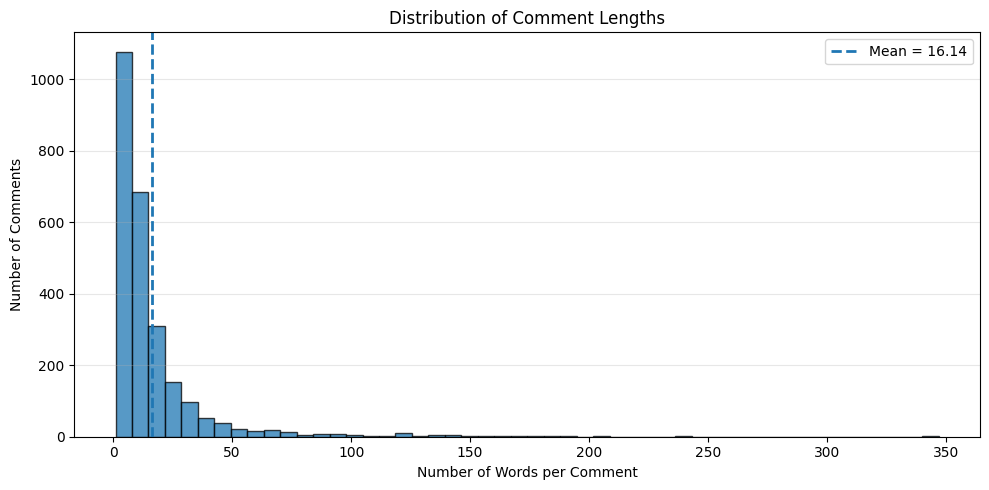

Mean number of words: 16.14


In [43]:
plt.figure(figsize=(10, 5))

plt.hist(
    CleanDF["n_words"].dropna(),
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    CleanDF["n_words"].mean(),
    linestyle="--",
    linewidth=2,
    label=f'Mean = {CleanDF["n_words"].mean():.2f}'
)

plt.xlabel("Number of Words per Comment")
plt.ylabel("Number of Comments")
plt.title("Distribution of Comment Lengths")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mean number of words: {CleanDF["n_words"].mean():.2f}")

In [36]:
# Filter comments with at least 2 words
CleanDF_filtered = CleanDF[CleanDF["n_words"] >= 2].copy()

# How many comments did not mention any keywords?
summary = pd.Series({
    "Positive": CleanDF_filtered["POS_words"].apply(len).gt(0).sum(),
    "Negative": CleanDF_filtered["NEG_words"].apply(len).gt(0).sum(),
    "Uncertainty": CleanDF_filtered["UNC_words"].apply(len).gt(0).sum(),
    "Non-keywords": (
        CleanDF_filtered[["POS_words", "NEG_words", "UNC_words"]]
        .apply(lambda col: col.apply(len).eq(0))
        .all(axis=1)
    ).sum()
})
summary.loc["Total posts"] = len(CleanDF_filtered)

total_posts = summary["Total posts"]
non_keywords = summary["Non-keywords"]

fraction_with_keywords = (total_posts - non_keywords) / total_posts

print(f"Fraction of posts with keywords (Keyword Coverage Rate): {fraction_with_keywords:.4f} "
      f"({fraction_with_keywords:.2%})")

Fraction of posts with keywords (Keyword Coverage Rate): 0.4741 (47.41%)


In [13]:
CleanDF.sample(n=3)

,datetime_et,body,POS_words,NEG_words,UNC_words
2261,2020-12-01 11:09:44-05:00,You guys won't believe how much BB I have in my account as of this week.,[],[],[BELIEVE]
2422,2020-12-01 09:18:58-05:00,Was there dd on bb calling this recently? Some of you got the memo.,[],[],[]
344,2020-12-07 15:13:17-05:00,I sold off my PLTR today and plan on using it on BB at close. This is easy money,[EASY],[SOLD],[]


In [41]:
# Filter comments with at least 2 words
CleanDF_filtered = CleanDF[CleanDF["n_words"] >= 17].copy()

# How many comments did not mention any keywords?
summary = pd.Series({
    "Positive": CleanDF_filtered["POS_words"].apply(len).gt(0).sum(),
    "Negative": CleanDF_filtered["NEG_words"].apply(len).gt(0).sum(),
    "Uncertainty": CleanDF_filtered["UNC_words"].apply(len).gt(0).sum(),
    "Non-keywords": (
        CleanDF_filtered[["POS_words", "NEG_words", "UNC_words"]]
        .apply(lambda col: col.apply(len).eq(0))
        .all(axis=1)
    ).sum()
})
summary.loc["Total posts"] = len(CleanDF_filtered)

total_posts = summary["Total posts"]
non_keywords = summary["Non-keywords"]

fraction_with_keywords = (total_posts - non_keywords) / total_posts

print(f"Fraction of posts with keywords (Keyword Coverage Rate): {fraction_with_keywords:.4f} "
      f"({fraction_with_keywords:.2%})")

Fraction of posts with keywords (Keyword Coverage Rate): 0.7166 (71.66%)


#### Are there ambiguous labels, i.e. tagged with more than 1 categories.

In [14]:
category_flags = pd.DataFrame({
    "Positive": CleanDF["POS_words"].apply(len).gt(0),
    "Negative": CleanDF["NEG_words"].apply(len).gt(0),
    "Uncertainty": CleanDF["UNC_words"].apply(len).gt(0)
})

# Count combinations among posts with multiple categories
multi_category_flags = category_flags[category_flags.sum(axis=1) > 1]

combination_counts = (
    multi_category_flags
    .astype(int)
    .value_counts()
)

print(combination_counts)

Positive  Negative  Uncertainty
1         1         0              165
          0         1               56
          1         1               48
0         1         1               28
Name: count, dtype: int64


In [15]:
mask = (
    CleanDF[["POS_words", "NEG_words", "UNC_words"]]
    .apply(lambda col: col.apply(len).gt(0))
    .sum(axis=1) >= 2
)

selectedDF = CleanDF[mask]
selectedDF[["body", "POS_words", "NEG_words", "UNC_words"]]

,body,POS_words,NEG_words,UNC_words
8,John Chen has a special talent for making **sales teams work better.** This was his principal accomplishment at Sybase. He knew that if he could become a big enough thorn in enough sides that Sybase would get picked up by a larger player for their IP and engineering talent - most of which was relegated to older mainframe based databases. \n\nBB's only real tech of value is QNX. Most of the value there is from the certifications that it has - which was politically helped along by the Canadian government. It competes against Android and especially [Automotive Grade Linux](https://www.automotivelinux.org). QNX cant compete against AGL in any meaningful way - I've worked with both. \n\nThe only real strategy Chen has to pursue here is to make it an attractive acquisition target to a old-world auto manufacturer looking to take a shortcut into producing electric vehicles. Thing is that every company that uses QNX in a car will be forever behind the competition on the feature side and cost side. \n\nShort BB.,"[ACCOMPLISHMENT, ATTRACTIVE, BETTER]","[AGAINST, SHORT]",[COULD]
13,BB has the cheapest fucking leaps. How are you losing? You’re supposed to buy low,[BUY],[LOSING],[]
41,Load up on $BB calls before it’s too late 🍑,[CALLS],[LATE],[]
42,"People forget about how John Chen turned Sybase around when he was CEO. Based on his track record he could really do some good things with BB.\n\n ""When John Chen signed on as CEO of [Sybase](https://www.computerworld.com/sybase) in 1998, the database software vendor was, in Chen's own words, ""a very, very dead company.” Once a strong competitor to Oracle, Sybase had lost its way, in part because it missed the opportunity to enter the enterprise application market [Oracle](http://www.oracle.com/index.html) now leads.\n\nOver the next decade, through the efforts of Chen and his team, Sybase turned around and reinvented itself as an enabler of the ""unwired enterprise."" Then, in mid-May, enterprise software giant [SAP signed a merger agreement with Sybase](https://www.computerworld.com/software/107750/sap-buys-sybase), citing Sybase's leadership in both mobile and in real-time analytics."" (SAP bought Sybase for $5.8 billion!!!)\n\nIf he can do it for Sybase he can do it for Blackberry. \n\n[https://www.computerworld.com/article/2758499/sybase-ceo-john-chen--tale-of-a-turnaround.html](https://www.computerworld.com/article/2758499/sybase-ceo-john-chen--tale-of-a-turnaround.html)","[GOOD, LEADERSHIP, OPPORTUNITY, STRONG]","[LOST, MISSED]","[COULD, MAY]"
47,BB seems weak. I have some calls that are boring af.,[CALLS],[WEAK],[SEEMS]
...,...,...,...,...
2507,@SJD10304: The S&P 500 gains 10% or more and closes the month at a new ATH monthly close? \n\nN=4\n\nNov-20\nDec-91\nJan-87\nNov-80\n\nNov 80 the only other match if we add closing the month above the upper monthly BB. \n\n(There's always something to keep us honest),[GAINS],[CLOSING],[]
2537,"It can walk the bands though, might be a good idea for a quick flip but I wouldn’t hold. Energy has been riding up and outside BB’s on the daily since like November started",[GOOD],[],[MIGHT]
2544,"Here is one of the reasons why BB has no value...\n\n""Global automaker Toyota Motors is dropping BlackBerry QNX’s infotainment software from its best-selling Camry vehicles in a move that analysts say reveals a growing threat to the technology company’s growing automotive business."" [https://www.obj.ca/article/blackberry-qnx-defensive-over-loss-toyota-open-source-linux-software](https://www.obj.ca/article/blackberry-qnx-defensive-over-loss-toyota-open-source-linux-software)\n\nWhy did Toyota dump BB for Linux? And how come BB is replaceable with even free software like Linux (if it's so good)? And that was 2017... I haven't heard anything about BB in 2020.\n\nThere is only one way out for BB... Guess that John China Wick doesn't know the answer yet.","[BEST, GOOD]","[DEFENSIVE, LOSS, THREAT]",[]
2546,"LOL BB was $5+ on Fri

#### Lets study the Non-keywords

In [16]:
### What is in the Non-keywords?

# Combine all dictionary keywords
ALL_KEYWORDS = POS | NEG | UNC


# Select posts containing no dictionary keywords
non_keyword_mask = (
    CleanDF[["POS_words", "NEG_words", "UNC_words"]]
    .apply(lambda col: col.apply(len).eq(0))
    .all(axis=1)
)

non_keyword_posts = CleanDF.loc[non_keyword_mask, "body"]

# Extract words and count their frequencies
word_counts = Counter()

for text in non_keyword_posts.dropna():
    words = re.findall(r"\b[A-Za-z]+\b", str(text).upper())
    word_counts.update(word for word in words if word not in ALL_KEYWORDS)

# Display the 50 most frequent words
most_common_words = pd.DataFrame(
    word_counts.most_common(10),
    columns=["Word", "Frequency"]
)

print(most_common_words)

  Word  Frequency
0   BB       1446
1  THE        318
2    I        308
3   IS        257
4   TO        246
5    A        200
6  YOU        178
7  AND        177
8   ON        169
9   IT        159


In [17]:
## Yea, see a lot of not informative words, get rid of them using..
STOPWORDS = {
    "THE", "IS", "AND", "TO", "A", "OF", "IN", "IT", "FOR",
    "ON", "I", "YOU", "THAT", "THIS", "BE", "ARE", "WAS",
    "WITH", "AS", "AT", "BUT", "HAVE", "HAS", "NOT", "SO",
    "MY", "ME", "YOUR", "WE", "THEY", "HE", "SHE", "OR",
    "IF", "JUST", "DO", "DID", "ABOUT", "WHAT", "ALL",
    "CAN", "WOULD", "SHOULD", "COULD", "FROM", "BY"
}

SPECIAL = {"BB"}

filtered_counts = {
    word: count
    for word, count in word_counts.items()
    if word not in (STOPWORDS | SPECIAL)
}

most_common_filtered = pd.DataFrame(
    Counter(filtered_counts).most_common(50),
    columns=["Word", "Frequency"]
)

print(most_common_filtered.head(10))

    Word  Frequency
0      S        121
1     UP         85
2      T         79
3      M         71
4   PLTR         69
5  GOING         57
6    NOW         56
7  TODAY         53
8    GET         50
9   MEME         49


In [18]:
## What people talk about when they mentioned CALL?
CleanDF[CleanDF["body"].str.contains("🚀", case=False, na=False)]

,datetime_et,body,POS_words,NEG_words,UNC_words
7,2020-12-08 18:20:15-05:00,"Never thought I’d say this but it’s 2020, $BB calls to the moon 🚀🚀🚀🚀","[CALLS, MOON]",[],[]
52,2020-12-08 15:18:42-05:00,I’m all in too🚀🚀🚀🚀🚀 Now we need solid memes for $BB to make it mainstream 😂😂,[],[],[]
56,2020-12-08 15:06:49-05:00,BB end of day run up get on board 🚀,[],[],[]
62,2020-12-08 14:56:50-05:00,BB 🚀 🚀 🚀,[],[],[]
69,2020-12-08 14:24:51-05:00,Buy BB for good luck 🚀,"[BUY, GOOD]",[],[]
...,...,...,...,...,...
2444,2020-12-01 09:09:17-05:00,I listened. Sitting on some dirt cheap contracts that are about to soar. Thank you. BB to the moon 🚀🚀🚀,"[MOON, SOAR]",[],[]
2511,2020-11-30 14:45:34-05:00,APHA all day bb 🚀,[],[],[]
2523,2020-11-30 11:06:57-05:00,This was the strongest and lowest dip you will see on this stock for a while. PLTR bb 🚀💰,"[DIP, STRONGEST]",[],[]
2533,2020-11-30 07:31:09-05:00,"I have just heard of this new stock, its called APPL, looks like its gonna be big.\n\nSYKE!\n\nPLTR bb 🚀🚀🚀🚀",[],[],[]


### Quantify the keywords

Problem: a lot of comments contain no POS/NEG/UNC words

In [19]:
TOKEN_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")

def lm_counts(text):
    """Return (n_words, n_pos, n_neg, n_unc) using exact LM word matches."""
    words = [w.upper() for w in TOKEN_RE.findall(str(text))]

    return (
        len(words),
        sum(w in POS for w in words),
        sum(w in NEG for w in words),
        sum(w in UNC for w in words)
    )

# Count words and dictionary matches for each post
counts = np.array([
    lm_counts(t) for t in CleanDF["body"].fillna("")
]).reshape(-1, 4)

CleanDF[["n_words", "n_pos", "n_neg", "n_unc"]] = counts

# Calculate tone in [-1, 1]
# Calculate tone
hits = CleanDF["n_pos"] + CleanDF["n_neg"]

no_keywords = (
    (CleanDF["n_pos"] == 0) &
    (CleanDF["n_neg"] == 0) &
    (CleanDF["n_unc"] == 0)
)

CleanDF["tone"] = np.where(
    no_keywords,
    -2.0,
    np.where(
        hits > 0,
        (CleanDF["n_pos"] - CleanDF["n_neg"]) / hits.clip(lower=1),
        0.0
    )
)

# Assign sentiment labels
CleanDF["label"] = np.select(
    [
        CleanDF["tone"] == -2,
        CleanDF["tone"] > 0,
        CleanDF["tone"] < 0
    ],
    ["no_keywords", "bullish", "bearish"],
    default="neutral"
)

# One-hot labels
CleanDF["p_bull"] = (CleanDF["label"] == "bullish").astype(float)
CleanDF["p_bear"] = (CleanDF["label"] == "bearish").astype(float)
CleanDF["p_neu"] = (CleanDF["label"] == "neutral").astype(float)

# Display results
CleanDF[[
    "datetime_et", "body",
    "n_words", "n_pos", "n_neg", "n_unc",
    "tone", "label"
]].head(10)

/tmp/ipykernel_650/3636780026.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  CleanDF[["n_words", "n_pos", "n_neg", "n_unc"]] = counts
/tmp/ipykernel_650/3636780026.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  CleanDF[["n_words", "n_pos", "n_neg", "n_unc"]] = counts
/tmp/ipykernel_650/3636780026.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://

,datetime_et,body,n_words,n_pos,n_neg,n_unc,tone,label
0,2020-12-08 18:59:47-05:00,BB got deaded,3,0,0,0,-2.0,no_keywords
1,2020-12-08 18:57:37-05:00,Someone should just make an ETF of Western companies with Asian CEOs. \n\nPerformance would be phenomenal. \n\nAMD\nNVDA\nBB\nZM\nGOOG\nMSFT\n\nAny I’m missing?,26,0,0,0,-2.0,no_keywords
2,2020-12-08 18:51:21-05:00,Shit I was born broke bb,6,0,0,0,-2.0,no_keywords
3,2020-12-08 18:49:17-05:00,I mean yeah tell us your bill thesis on BB,10,0,0,0,-2.0,no_keywords
4,2020-12-08 18:46:33-05:00,"IV is so fucking high right now, I’m not touching that. I’m balls deep in BB anyway",19,0,0,0,-2.0,no_keywords
5,2020-12-08 18:32:56-05:00,You good bb. Don't even need to come market tomorrow. Take high roller vacation. Cruise recommended,16,1,0,0,1.0,bullish
6,2020-12-08 18:31:32-05:00,BB,1,0,0,0,-2.0,no_keywords
7,2020-12-08 18:20:15-05:00,"Never thought I’d say this but it’s 2020, $BB calls to the moon 🚀🚀🚀🚀",14,2,0,0,1.0,bullish
8,2020-12-08 18:15:21-05:00,John Chen has a special talent for making **sales teams work better.** This was his principal accomplishment at Sybase. He knew that if he could become a big enough thorn in enough sides that Sybase would get picked up by a larger player for their IP and engineering talent - most of which was relegated to older mainframe based databases. \n\nBB's only real tech of value is QNX. Most of the value there is from the certifications that it has - which was politically helped along by the Canadian government. It competes against Android and especially [Automotive Grade Linux](https://www.automotivelinux.org). QNX cant compete against AGL in any meaningful way - I've worked with both. \n\nThe only real strategy Chen has to pursue here is to make it an attractive acquisition target to a old-world auto manufacturer looking to take a shortcut into producing electric vehicles. Thing is that every company that uses QNX in a car will be forever behind the competition on the feature side and cost side. \n\nShort BB.,172,3,3,1,0.0,neutral
9,2020-12-08 18:15:10-05:00,16.34 average with 1k shares bb,5,0,0,0,-2.0,no_keywords


In [20]:
print(CleanDF["label"].value_counts())

print(
    CleanDF["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .astype(str)
    .add("%")
)

label
no_keywords    1402
bullish         700
bearish         266
neutral         188
Name: count, dtype: int64
label
no_keywords    54.85%
bullish        27.39%
bearish        10.41%
neutral         7.36%
Name: proportion, dtype: object


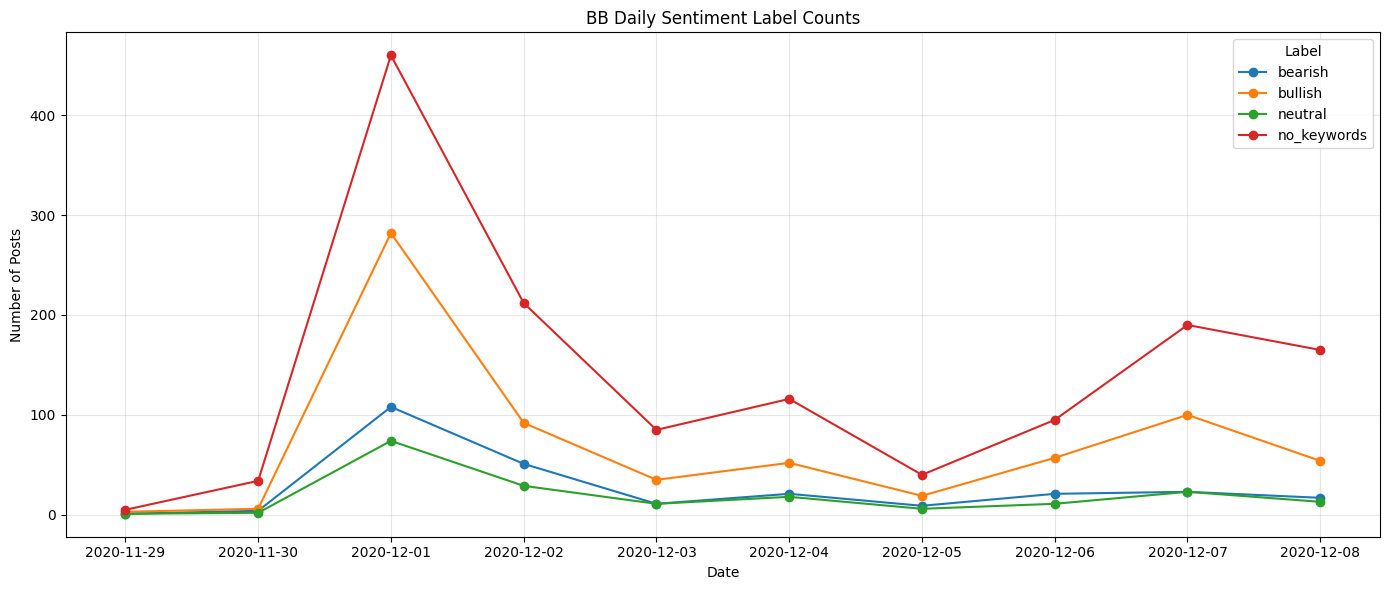

In [42]:
# Ensure datetime is parsed correctly
CleanDF["datetime_et"] = pd.to_datetime(CleanDF["datetime_et"])

# Count posts per day and label
daily_counts = (
    CleanDF.groupby([
        CleanDF["datetime_et"].dt.date,
        "label"
    ])
    .size()
    .unstack(fill_value=0)
)

# Plot
daily_counts.plot(figsize=(14, 6), marker="o")

plt.xlabel("Date")
plt.ylabel("Number of Posts")
plt.title("BB Daily Sentiment Label Counts")
plt.legend(title="Label")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

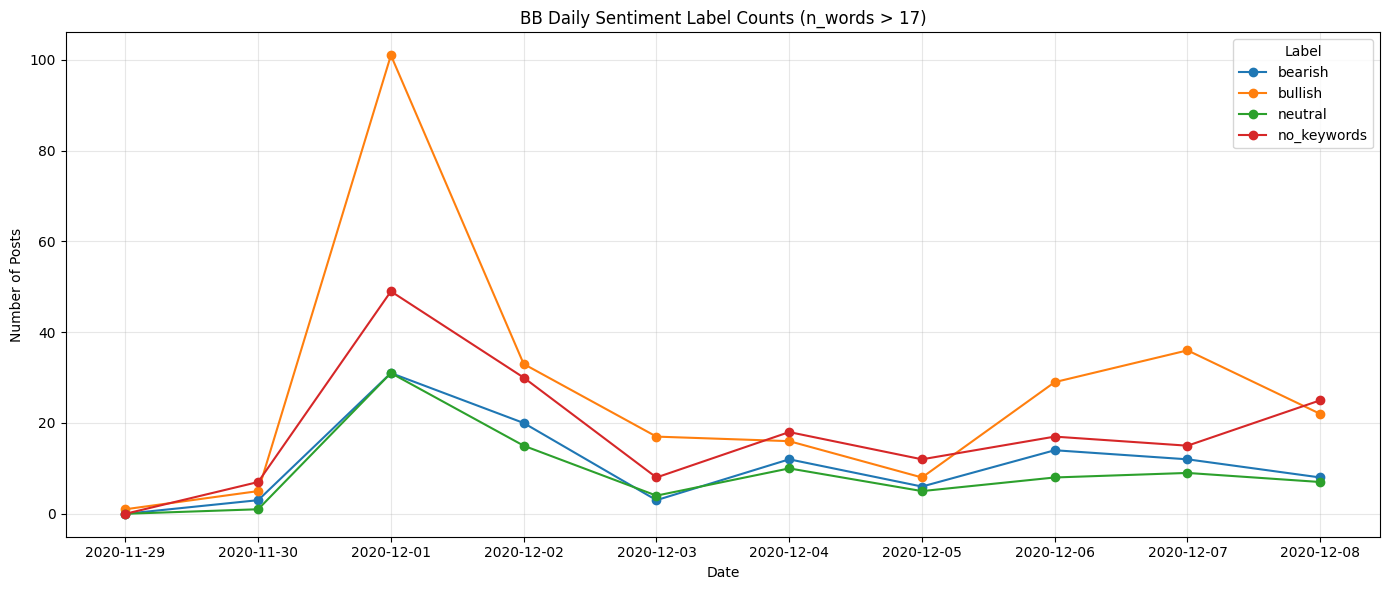

In [47]:
# Ensure datetime is parsed correctly
CleanDF["datetime_et"] = pd.to_datetime(CleanDF["datetime_et"])

# Filter comments with more than 17 words
df_filtered = CleanDF[CleanDF["n_words"] > 17]

# Count posts per day and label
daily_counts = (
    df_filtered.groupby([
        df_filtered["datetime_et"].dt.date,
        "label"
    ])
    .size()
    .unstack(fill_value=0)
)

# Plot
daily_counts.plot(figsize=(14, 6), marker="o")

plt.xlabel("Date")
plt.ylabel("Number of Posts")
plt.title("BB Daily Sentiment Label Counts (n_words > 17)")
plt.legend(title="Label")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

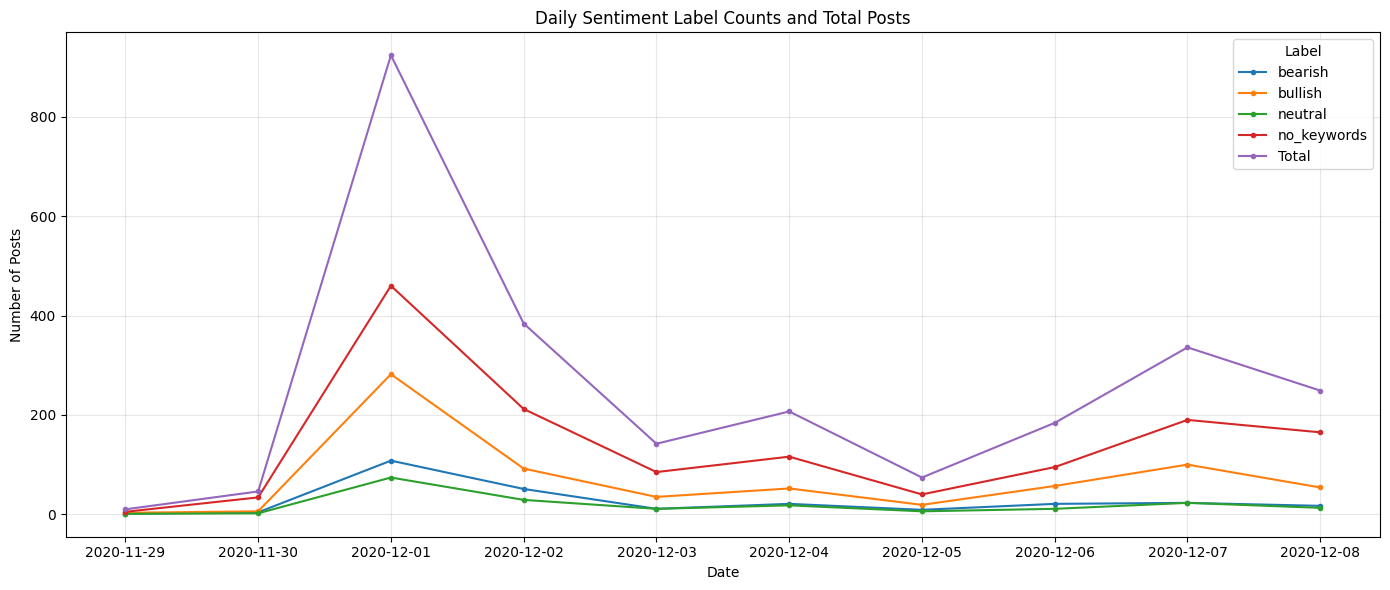

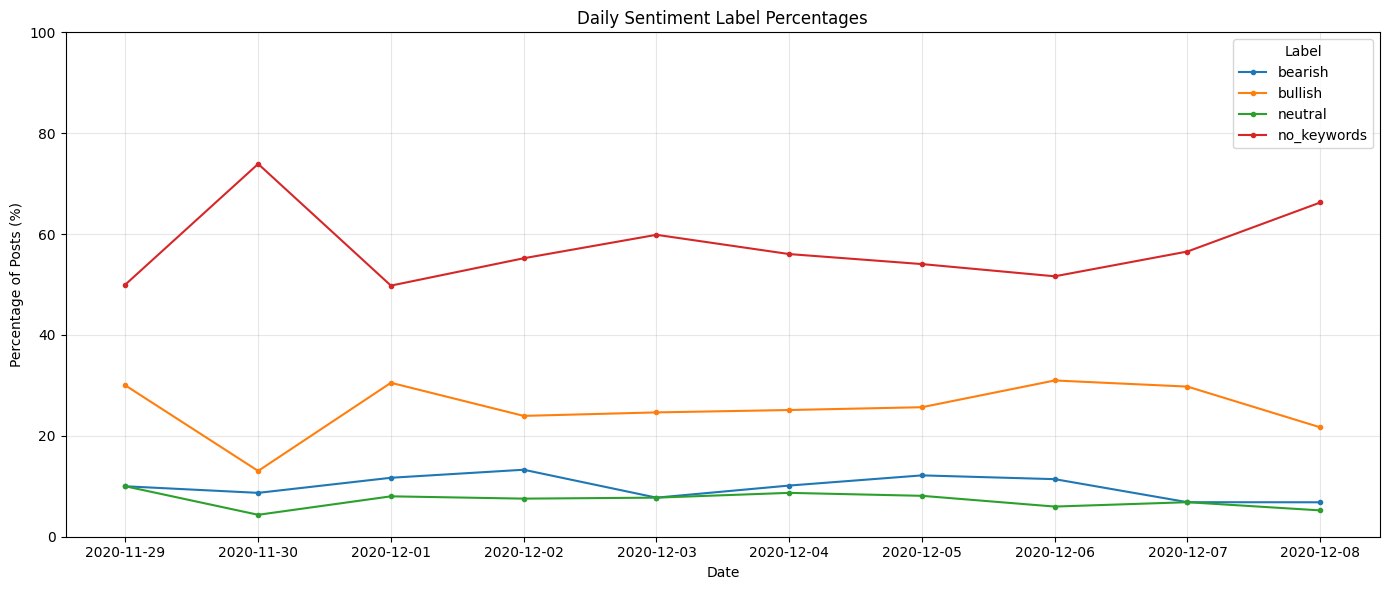

In [22]:
# Ensure datetime is parsed correctly
CleanDF["datetime_et"] = pd.to_datetime(CleanDF["datetime_et"])

# Count posts per day and label
daily_counts = (
    CleanDF.groupby([
        CleanDF["datetime_et"].dt.date.rename("date"),
        "label"
    ])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Calculate total posts per day
daily_counts["Total"] = daily_counts.sum(axis=1)

# --------------------------------------------------
# Plot 1: Daily counts, including total posts
# --------------------------------------------------
daily_counts.plot(figsize=(14, 6), marker="o", markersize=3)

plt.xlabel("Date")
plt.ylabel("Number of Posts")
plt.title("Daily Sentiment Label Counts and Total Posts")
plt.legend(title="Label")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Plot 2: Percentage of each category per day
# --------------------------------------------------
category_counts = daily_counts.drop(columns="Total")

daily_percentages = (
    category_counts
    .div(daily_counts["Total"], axis=0)
    .mul(100)
)

ax = daily_percentages.plot(
    figsize=(14, 6),
    marker="o",
    markersize=3
)

plt.xlabel("Date")
plt.ylabel("Percentage of Posts (%)")
plt.title("Daily Sentiment Label Percentages")
plt.ylim(0, 100)
plt.legend(title="Label")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Assign a daily sentiment score

Define the daily sentiment score as:
$$S_d = \frac{N_{\text{bullish},d}-N_{\text{bearish},d}}
{N_{\text{bullish},d}+N_{\text{bearish},d}+N_{\text{neutral},d}}$$

In [23]:
# Extract the calendar date in Eastern Time
CleanDF["date"] = pd.to_datetime(CleanDF["datetime_et"]).dt.date

# Assign numerical scores
score_map = {
    "bullish": 1,
    "neutral": 0,
    "bearish": -1
}

CleanDF["sentiment_score"] = CleanDF["label"].map(score_map)

# Calculate daily sentiment
daily_sentiment = (
    CleanDF.dropna(subset=["sentiment_score"])
    .groupby("date")
    .agg(
        n_bull=("label", lambda x: (x == "bullish").sum()),
        n_bear=("label", lambda x: (x == "bearish").sum()),
        n_neutral=("label", lambda x: (x == "neutral").sum()),
        mean_sentiment=("sentiment_score", "mean")
    )
    .reset_index()
)

daily_sentiment = daily_sentiment.rename(
    columns={"mean_sentiment": "sentiment"}
)

daily_sentiment.head()

,date,n_bull,n_bear,n_neutral,sentiment
0,2020-11-29,3,1,1,0.400000
1,2020-11-30,6,4,2,0.166667
2,2020-12-01,282,108,74,0.375000
3,2020-12-02,92,51,29,0.238372
4,2020-12-03,35,11,11,0.421053


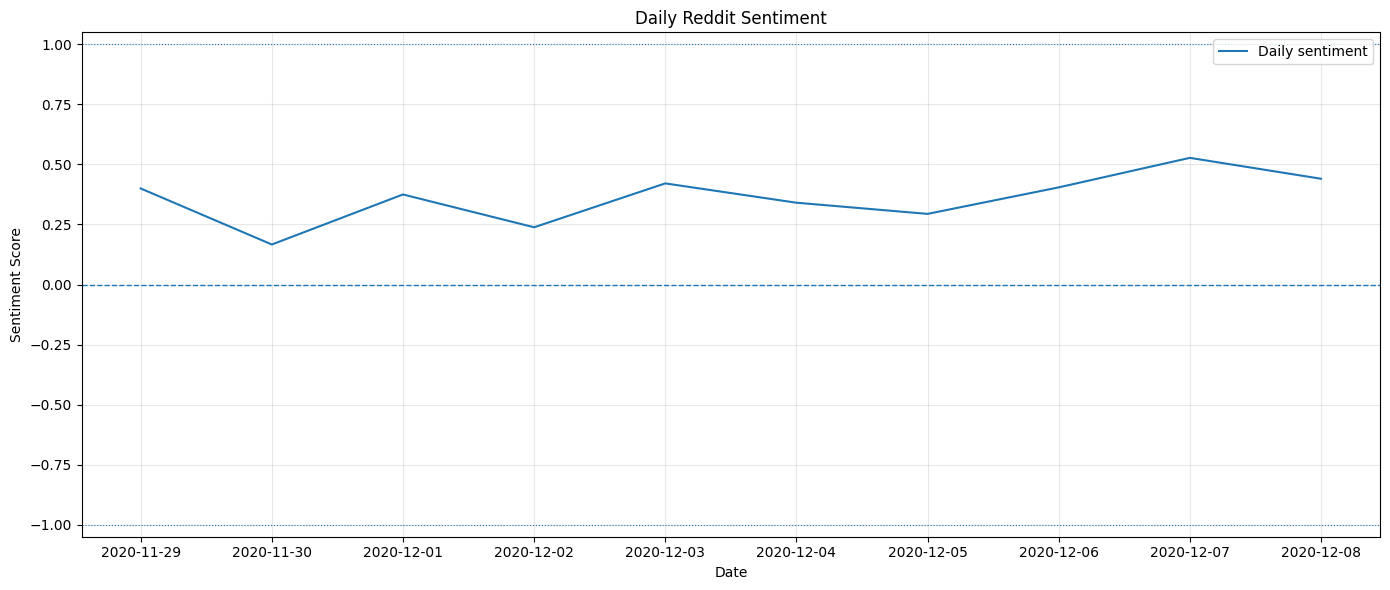

In [24]:
# Plot it
daily_sentiment = daily_sentiment.sort_values("date")

plt.figure(figsize=(14, 6))
plt.plot(
    pd.to_datetime(daily_sentiment["date"]),
    daily_sentiment["sentiment"],
    linewidth=1.5,
    label="Daily sentiment"
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.axhline(1, linestyle=":", linewidth=0.8)
plt.axhline(-1, linestyle=":", linewidth=0.8)

plt.xlabel("Date")
plt.ylabel("Sentiment Score")
plt.title("Daily Reddit Sentiment")
plt.ylim(-1.05, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

#### Repeat the process of sentiment score calculation

but this time, apply it on systematic subgroups of data.

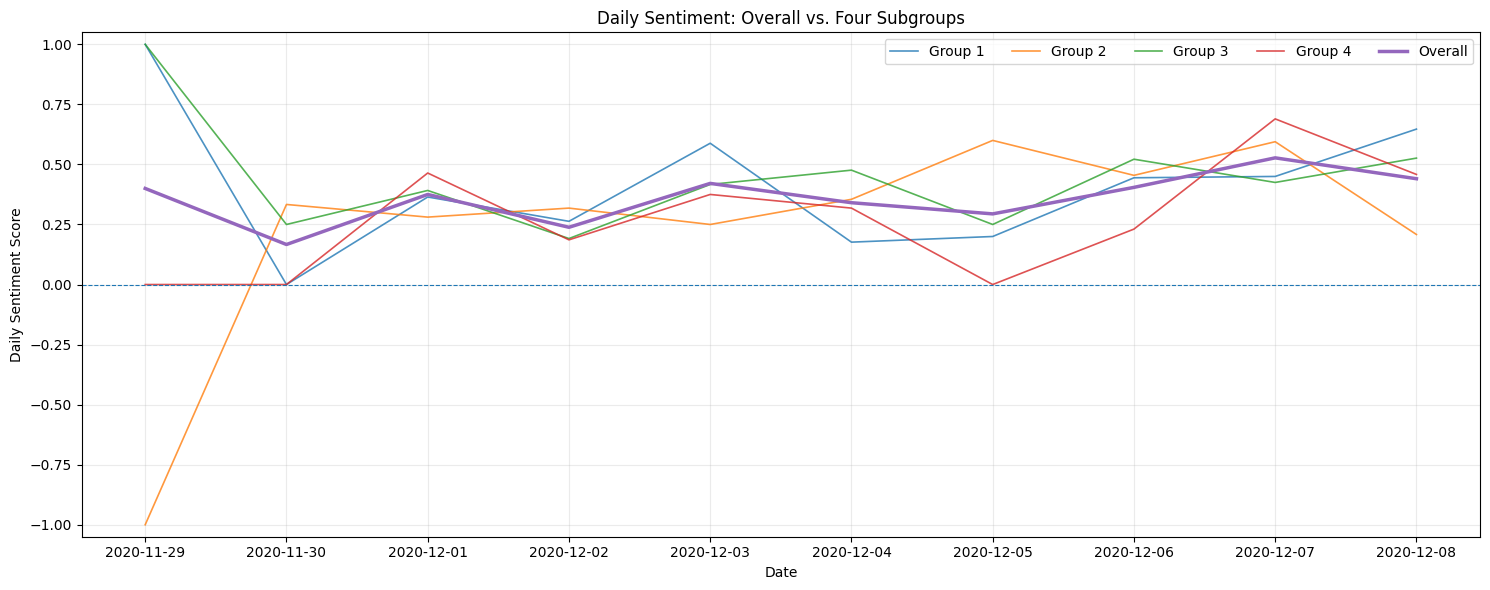

In [25]:
df = CleanDF.copy()

# Extract date in Eastern Time
df["date"] = pd.to_datetime(df["datetime_et"]).dt.date

# Systematically divide rows into four subgroups
df["subgroup"] = np.arange(len(df)) % 4 + 1

# Convert sentiment labels to numerical scores
score_map = {
    "bullish": 1,
    "neutral": 0,
    "bearish": -1
}

df["sentiment_score"] = df["label"].map(score_map)

# Exclude rows without a valid sentiment label
df = df.dropna(subset=["sentiment_score"])


## Calculate sentiment score
daily = (
    df.groupby(["date", "subgroup"])["sentiment_score"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

# Pivot subgroup sentiment into separate columns
daily_wide = daily.pivot(
    index="date",
    columns="subgroup",
    values="mean"
)

daily_wide.columns = [f"Group {i}" for i in daily_wide.columns]

# Calculate overall daily sentiment
overall = (
    df.groupby("date")["sentiment_score"]
    .mean()
    .rename("Overall")
)

daily_wide = daily_wide.join(overall).sort_index()

groups = ["Group 1", "Group 2", "Group 3", "Group 4"]
dates = pd.to_datetime(daily_wide.index)

plt.figure(figsize=(15, 6))

# Plot four subgroups
for group in groups:
    plt.plot(
        dates,
        daily_wide[group],
        linewidth=1.2,
        alpha=0.8,
        label=group
    )

# Plot overall sentiment
plt.plot(
    dates,
    daily_wide["Overall"],
    linewidth=2.5,
    label="Overall"
)

plt.axhline(0, linestyle="--", linewidth=0.8)
plt.xlabel("Date")
plt.ylabel("Daily Sentiment Score")
plt.title("Daily Sentiment: Overall vs. Four Subgroups")
plt.ylim(-1.05, 1.05)
plt.legend(ncol=5)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

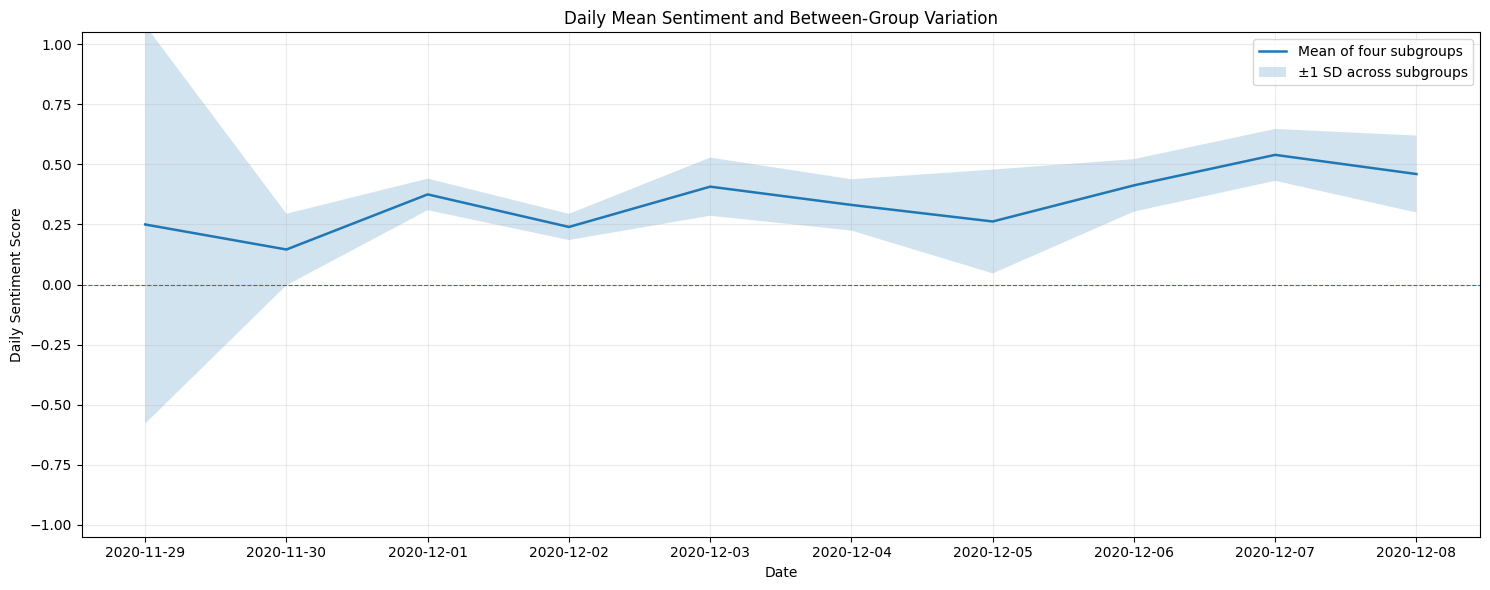

In [26]:
# Daily mean and standard deviation across subgroups
daily_mean = daily_wide[groups].mean(axis=1)
daily_std = daily_wide[groups].std(axis=1, ddof=0)

plt.figure(figsize=(15, 6))

plt.plot(
    dates,
    daily_mean,
    linewidth=1.8,
    label="Mean of four subgroups"
)

plt.fill_between(
    dates,
    daily_mean - daily_std,
    daily_mean + daily_std,
    alpha=0.2,
    label="±1 SD across subgroups"
)

plt.axhline(0, linestyle="--", linewidth=0.8)
plt.xlabel("Date")
plt.ylabel("Daily Sentiment Score")
plt.title("Daily Mean Sentiment and Between-Group Variation")
plt.ylim(-1.05, 1.05)
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [27]:
# Mean and standard deviation of daily sentiment over time
group_mean = daily_wide[groups].mean(axis=0)
group_std = daily_wide[groups].std(axis=0)

summary = pd.DataFrame({
    "Mean_Daily_Sentiment": group_mean,
    "SD_Daily_Sentiment": group_std,
    "Min_Daily_Sentiment": daily_wide[groups].min(),
    "Max_Daily_Sentiment": daily_wide[groups].max(),
    "Available_Days": daily_wide[groups].count()
})

summary.round(4)

,Mean_Daily_Sentiment,SD_Daily_Sentiment,Min_Daily_Sentiment,Max_Daily_Sentiment,Available_Days
Group 1,0.4134,0.2846,0.0000,1.0000,10
Group 2,0.2395,0.4558,-1.0000,0.6000,10
Group 3,0.4449,0.2275,0.1915,1.0000,10
Group 4,0.2722,0.2333,0.0000,0.6897,10


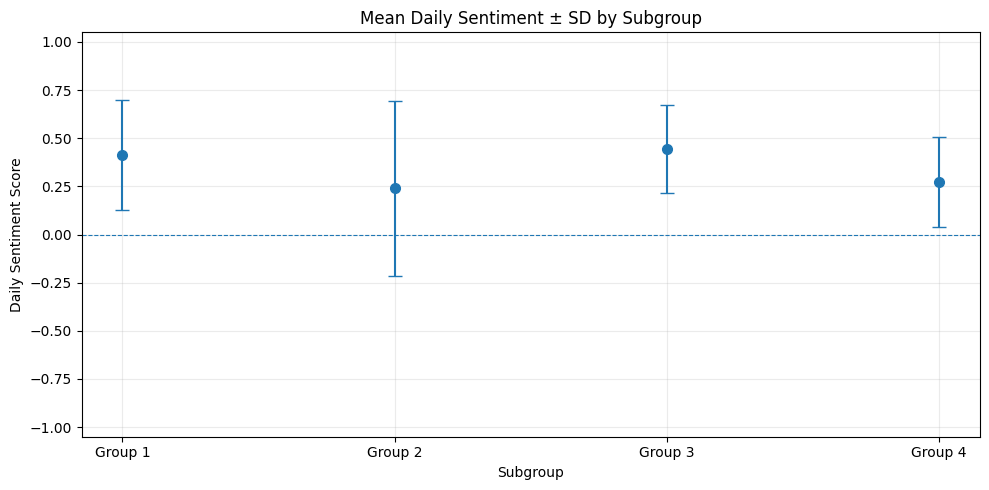

In [28]:
# Plot means as points and standard deviations as error bars
plt.figure(figsize=(10, 5))

plt.errorbar(
    groups,
    group_mean.values,
    yerr=group_std.values,
    fmt="o",
    capsize=5,
    markersize=7,
    linestyle="none"
)

plt.axhline(0, linestyle="--", linewidth=0.8)
plt.xlabel("Subgroup")
plt.ylabel("Daily Sentiment Score")
plt.title("Mean Daily Sentiment ± SD by Subgroup")
plt.ylim(-1.05, 1.05)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

Now this comes to the performance, we want to know how reliable of this method, i.e. how accurate can it be if I randomly select samples to calculate the sentiment score of a given day.

A good method should give consistent results with small standard variation across different subgroups.

At the end, we look at the mean of the standard variation of all the days, to quantify the performance.

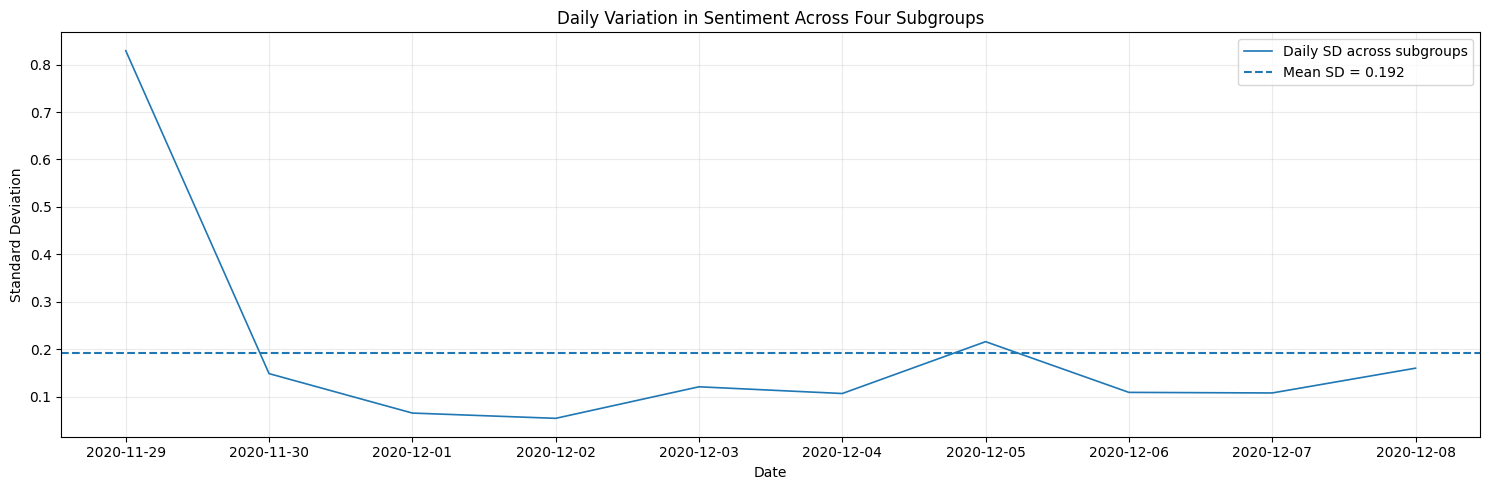

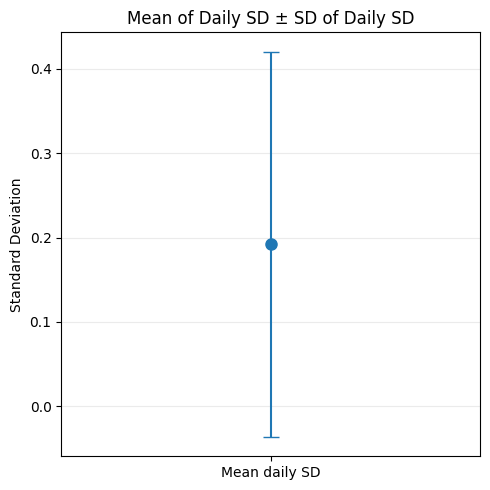

Mean daily SD: 0.1920
SD of daily SD: 0.2286


In [29]:
# Daily standard deviation across the four subgroups
daily_std = daily_wide[groups].std(axis=1, ddof=0)

# Mean and standard deviation of the daily standard deviations
mean_std = daily_std.mean()
std_of_std = daily_std.std()

# Plot daily standard deviation over time
plt.figure(figsize=(15, 5))

plt.plot(
    dates,
    daily_std,
    linewidth=1.2,
    label="Daily SD across subgroups"
)

plt.axhline(
    mean_std,
    linestyle="--",
    linewidth=1.5,
    label=f"Mean SD = {mean_std:.3f}"
)

plt.xlabel("Date")
plt.ylabel("Standard Deviation")
plt.title("Daily Variation in Sentiment Across Four Subgroups")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

# Plot mean standard deviation as a point with an error bar
plt.figure(figsize=(5, 5))

plt.errorbar(
    ["Mean daily SD"],
    [mean_std],
    yerr=[std_of_std],
    fmt="o",
    capsize=6,
    markersize=8,
    linestyle="none"
)

plt.ylabel("Standard Deviation")
plt.title("Mean of Daily SD ± SD of Daily SD")
plt.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Mean daily SD: {mean_std:.4f}")
print(f"SD of daily SD: {std_of_std:.4f}")

NameError: name 'plot_dates' is not defined

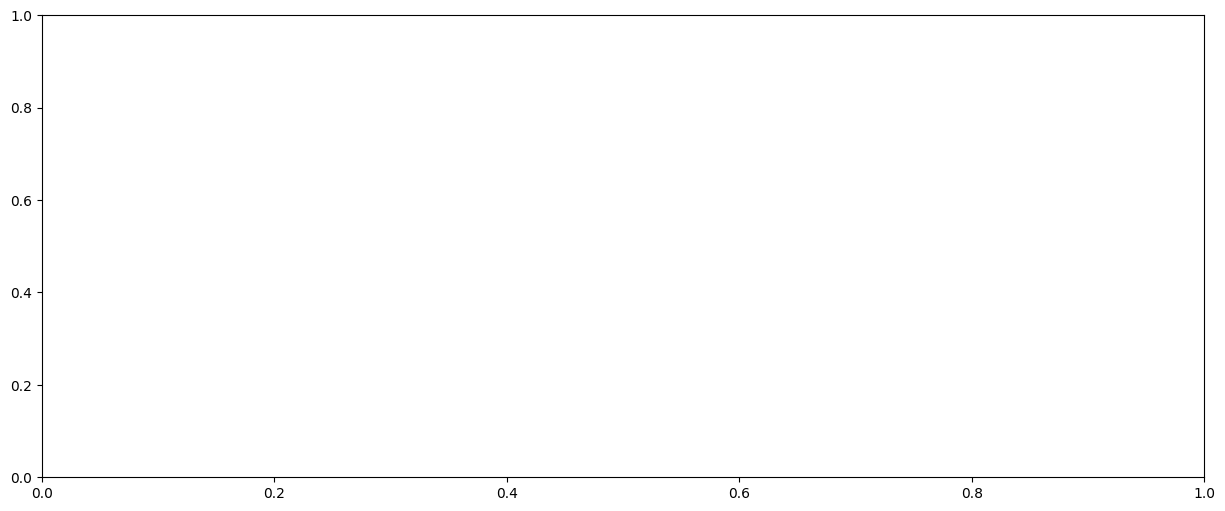

In [30]:
# Overlay with daily post volume, and see if there are correlations
fig, ax1 = plt.subplots(figsize=(15, 6))

# Left axis: daily standard deviation
line1, = ax1.plot(
    plot_dates,
    plot_data["daily_std"],
    color="tab:blue",
    linewidth=2.5,
    linestyle="-",
    label="Daily SD across subgroups",
    zorder=3
)

mean_line = ax1.axhline(
    mean_std,
    color="tab:blue",
    linestyle=":",
    linewidth=2,
    label=f"Mean SD = {mean_std:.3f}",
    zorder=2
)

ax1.set_xlabel("Date", fontsize=12)
ax1.set_ylabel("Standard Deviation", color="tab:blue", fontsize=12)
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.grid(True, linestyle="--", alpha=0.25)

# Right axis: normalized total post count
ax2 = ax1.twinx()

line2, = ax2.plot(
    plot_dates,
    plot_data["total_posts_normalized"],
    color="tab:orange",
    linewidth=2.5,
    linestyle="-",
    label="Total posts (normalized)",
    zorder=4
)

ax2.set_ylabel("Normalized Total Posts", color="tab:orange", fontsize=12)
ax2.tick_params(axis="y", labelcolor="tab:orange")
ax2.set_ylim(0, 1.05)

# Combined legend
lines = [line1, mean_line, line2]
labels = [line.get_label() for line in lines]

ax1.legend(
    lines,
    labels,
    loc="upper left",
    frameon=True,
    framealpha=0.95,
    fontsize=10
)

plt.title(
    "Daily Sentiment Variation vs. Post Volume",
    fontsize=14,
    pad=12
)

plt.tight_layout()
plt.show()

print(f"Mean daily between-subgroup standard deviation of sentiment scores:{std_of_std:.4f}")